# A prorrogação do horário no segundo turno de 2026

Na tarde de 25/10/2026, depois de as duas campanhas relatarem problemas de transporte de eleitores (e a de Flávio Bolsonaro, chuva e alagamentos em municípios de SP, PR e SC), o ministro Cristiano Zanin (STF) prorrogou a votação do segundo turno de 17h para 19h. A decisão saiu pouco depois das 17h, foi lida primeiro como valendo para todo o país e depois restrita às seções que ainda estavam com a urna aberta. O TSE suspendeu a divulgação dos resultados até 19h.

As perguntas deste notebook:

1. **Quantas seções de fato votaram depois das 17h**, e quanto isso foge do normal (no 1º turno, sem prorrogação, sempre há seções que fecham depois por causa de fila)?
2. **Onde** elas ficaram abertas?
3. **A prorrogação poderia ter decidido a eleição?** Lula venceu por 4,43 milhões de votos.

**Dados:** boletim de urna (`bweb`) dos dados abertos do TSE, que traz a hora de abertura e de encerramento de cada urna. Rode `src/download_bweb.py 1` e `src/download_bweb.py 2` antes deste notebook. O horário é convertido para o de Brasília (a votação abre às 8h de Brasília em todo o país, e o bweb registra a hora local).

**Limite de partida:** o boletim diz quando a urna fechou, não quantos eleitores votaram depois das 17h. Esse número exato está nos logs das urnas, que o notebook não usa. Por isso a seção 3 trabalha com limites e com comparação entre turnos.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

pd.options.display.float_format = "{:,.3f}".format
PROC = Path("../data/processed")
LULA, FLAVIO, CINZA, T1 = "#2a78d6", "#eb6834", "#8a8984", "#9ec5f4"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9c8c2",
    "axes.grid": True, "grid.color": "#e8e7e2", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "font.size": 10, "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "legend.frameon": False,
})
CHAVE = ["SG_UF", "CD_MUNICIPIO", "NR_ZONA", "NR_SECAO"]

def carregar(turno):
    path = PROC / f"secao_presidente_{turno}t.csv"
    if not path.exists():
        print(f"{path} não existe: rode src/download_bweb.py {turno}")
        return None
    d = pd.read_csv(path, parse_dates=["abertura_bsb", "encerramento_bsb"], low_memory=False)
    dia = d.abertura_bsb.dt.normalize().mode()[0]
    # minutos depois das 17h de Brasília em que a urna foi encerrada
    d["min_apos_17h"] = (d.encerramento_bsb - (dia + pd.Timedelta(hours=17))).dt.total_seconds() / 60
    d["turno"] = turno
    return d

s1, s2 = carregar(1), carregar(2)
TEM_2T = s2 is not None
for s in (s1, s2):
    if s is not None:
        print(f"{s.turno.iloc[0]}º turno: {len(s):,} seções, {s.QT_APTOS.sum():,} aptos, "
              f"{s.QT_COMPARECIMENTO.sum():,} votantes, sem horário: {s.min_apos_17h.isna().sum()}")
        print("   tipo de urna:", s.DS_TIPO_URNA.value_counts().to_dict())

../data/processed/secao_presidente_2t.csv não existe: rode src/download_bweb.py 2
1º turno: 499,206 seções, 158,745,007 aptos, 125,275,835 votantes, sem horário: 30
   tipo de urna: {'Apurada': 499206}


## 1. Quantas seções fecharam depois das 17h

A urna não fecha exatamente às 17h: o mesário encerra depois de votar quem estava na fila às 17h, e o encerramento em si leva alguns minutos. Então "depois das 17h" precisa ser comparado com o 1º turno, que teve as mesmas regras e nenhuma prorrogação.

In [2]:
LIMIARES = [10, 30, 60, 90, 120]

def resumo_atraso(s):
    out = {}
    for m in LIMIARES:
        late = s.min_apos_17h > m
        out[f"depois de 17h{m:02d}" if m < 60 else f"depois de {17 + m // 60}h{m % 60:02d}"] = {
            "seções": late.sum(), "% das seções": late.mean(),
            "eleitores aptos nessas seções": s.loc[late, "QT_APTOS"].sum(),
            "votantes nessas seções": s.loc[late, "QT_COMPARECIMENTO"].sum()}
    return pd.DataFrame(out).T

tabs = {f"{t}º turno": resumo_atraso(s) for t, s in ((1, s1), (2, s2)) if s is not None}
tab = pd.concat(tabs, axis=1)
display(tab.style.format("{:,.0f}").format("{:.2%}", subset=[c for c in tab.columns if c[1] == "% das seções"]))

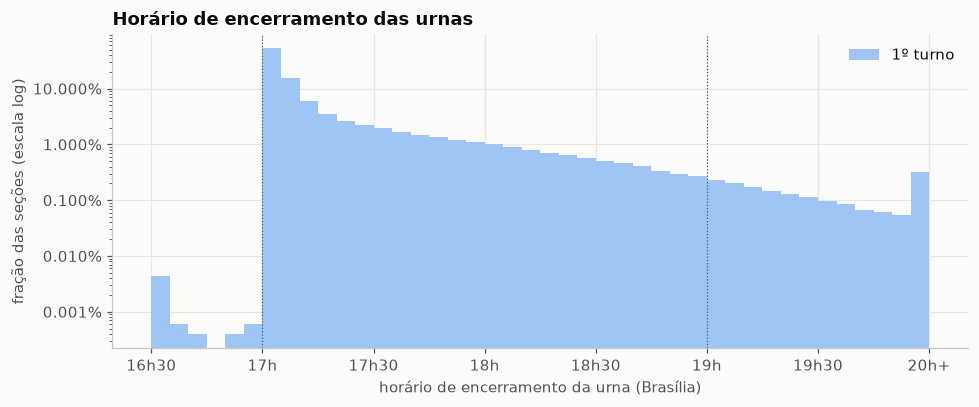

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.8))
bins = np.arange(-30, 181, 5)
for s, cor, nome in ((s1, T1, "1º turno"), (s2, LULA, "2º turno")):
    if s is None:
        continue
    x = s.min_apos_17h.clip(bins[0], bins[-1])
    ax.hist(x, bins=bins, color=cor, alpha=0.9 if nome == "2º turno" else 1, label=nome,
            weights=np.full(len(x), 1 / len(x)))
ax.set_yscale("log")
ax.axvline(0, color="#52514e", lw=0.8, ls=":"); ax.axvline(120, color="#52514e", lw=0.8, ls=":")
ax.set_xticks(range(-30, 181, 30), ["16h30", "17h", "17h30", "18h", "18h30", "19h", "19h30", "20h+"])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.3%}".rstrip("0").rstrip(".")))
ax.set_ylabel("fração das seções (escala log)"); ax.set_xlabel("horário de encerramento da urna (Brasília)")
ax.set_title("Horário de encerramento das urnas"); ax.legend()
plt.tight_layout(); plt.show()

## 2. Onde as urnas ficaram abertas

Uso como "seção atrasada" a que fechou depois de 17h30 de Brasília. O limiar é arbitrário; a tabela da seção 1 mostra como os números mudam com ele.

In [4]:
LIMIAR = 30
REGIAO = {
    **dict.fromkeys("AC AP AM PA RO RR TO".split(), "Norte"),
    **dict.fromkeys("AL BA CE MA PB PE PI RN SE".split(), "Nordeste"),
    **dict.fromkeys("DF GO MT MS".split(), "Centro-Oeste"),
    **dict.fromkeys("ES MG RJ SP".split(), "Sudeste"),
    **dict.fromkeys("PR RS SC".split(), "Sul"),
    "ZZ": "Exterior",
}

def por_uf(s):
    s = s.assign(atrasada=s.min_apos_17h > LIMIAR)
    g = s.groupby("SG_UF").agg(secoes=("atrasada", "size"), atrasadas=("atrasada", "sum"))
    g["% atrasadas"] = g.atrasadas / g.secoes
    return g

ufs = pd.concat({f"{t}º turno": por_uf(s) for t, s in ((1, s1), (2, s2)) if s is not None}, axis=1)
ordem = ufs.columns[-1]
display(ufs.sort_values((ordem[0], "% atrasadas"), ascending=False).style
        .format("{:,.0f}").format("{:.1%}", subset=[c for c in ufs.columns if c[1] == "% atrasadas"]))

In [5]:
ult = s2 if TEM_2T else s1
mun = (ult.assign(atrasada=ult.min_apos_17h > LIMIAR)
       .groupby(["SG_UF", "NM_MUNICIPIO"])
       .agg(secoes=("atrasada", "size"), atrasadas=("atrasada", "sum"),
            votantes_atrasadas=("QT_COMPARECIMENTO", lambda x: x[ult.loc[x.index, "min_apos_17h"] > LIMIAR].sum()),
            ultima=("encerramento_bsb", "max")))
mun["% atrasadas"] = mun.atrasadas / mun.secoes
print(f"Municípios com mais seções atrasadas ({ult.turno.iloc[0]}º turno):")
display(mun.nlargest(20, "atrasadas").style.format({"% atrasadas": "{:.0%}", "ultima": "{:%H:%M}"}))

Municípios com mais seções atrasadas (1º turno):


,,secoes,atrasadas,votantes_atrasadas,ultima,% atrasadas
SG_UF,NM_MUNICIPIO,,,,,
RJ,RIO DE JANEIRO,12635,5068,1615884,20:54,40%
CE,FORTALEZA,5335,2077,672289,20:10,39%
BA,SALVADOR,5124,1822,603764,20:21,36%
AM,MANAUS,4013,1727,558600,21:16,43%
PE,RECIFE,3481,1256,407116,20:00,36%
AL,MACEIÓ,1661,860,300038,21:11,52%
MA,SÃO LUÍS,2273,844,259081,20:03,37%
RN,NATAL,1477,819,270012,20:22,55%
MG,BELO HORIZONTE,4927,782,270345,19:35,16%


## 3. A prorrogação poderia ter decidido a eleição?

Três contas, da mais grosseira para a mais fina.

**(a) Teto absoluto.** Mesmo que todo eleitor de toda seção atrasada tivesse votado depois das 17h, e todos em Lula, quanto isso somaria? Se for menos que a margem de 4,43 milhões, a prorrogação não pode ter mudado o vencedor, sob nenhuma hipótese.

**(b) A margem dentro das seções atrasadas.** Quanto Lula ganhou ou perdeu nessas seções, comparando com o resto.

**(c) Comparecimento extra.** Comparando cada seção com ela mesma no 1º turno: as seções que fecharam tarde no 2º turno tiveram um aumento de comparecimento maior que as outras do mesmo município? Esse excesso é uma estimativa de quantos eleitores votaram *por causa* da janela extra.

In [6]:
if TEM_2T:
    margem = (s2.lula - s2.flavio).sum()
    for m in LIMIARES:
        late = s2.min_apos_17h > m
        print(f"fechou depois de 17h+{m:>3} min: {late.sum():>6,} seções, {s2.loc[late, 'QT_COMPARECIMENTO'].sum():>10,} votantes "
              f"→ {s2.loc[late, 'QT_COMPARECIMENTO'].sum() / margem:.1%} da margem nacional; "
              f"margem de Lula nessas seções: {(s2.lula - s2.flavio)[late].sum():+,}")
    print(f"\nmargem nacional de Lula no bweb: {margem:,}")
else:
    print("Esta seção precisa do bweb do 2º turno.")

Esta seção precisa do bweb do 2º turno.


In [7]:
if TEM_2T:
    p = s2.merge(s1[CHAVE + ["QT_COMPARECIMENTO", "QT_APTOS", "lula", "flavio", "min_apos_17h"]],
                 on=CHAVE, suffixes=("", "_1t"))
    p = p[(p.QT_APTOS > 0) & (p.QT_APTOS_1t > 0)]
    p["comp_1t"] = p.QT_COMPARECIMENTO_1t / p.QT_APTOS_1t
    p["comp_2t"] = p.QT_COMPARECIMENTO / p.QT_APTOS
    p["d_comp"] = (p.comp_2t - p.comp_1t) * 100
    p["atrasada_2t"] = (p.min_apos_17h > LIMIAR).astype(int)
    p["atrasada_1t"] = (p.min_apos_17h_1t > LIMIAR).astype(int)
    p["h2h_2t"] = p.lula / (p.lula + p.flavio) * 100
    p["h2h_1t"] = p.lula_1t / (p.lula_1t + p.flavio_1t) * 100
    p["mun"] = p.SG_UF + p.CD_MUNICIPIO.astype(str)
    p["local"] = p.mun + "-" + p.NR_ZONA.astype(str) + "-" + p.NR_LOCAL_VOTACAO.astype(str)
    print(f"{len(p):,} seções pareadas entre os turnos")

    # comparação dentro do mesmo município, controlando se a seção já atrasava no 1º turno
    fx = smf.wls("d_comp ~ atrasada_2t + atrasada_1t + comp_1t + C(mun)", data=p, weights=p.QT_APTOS) \
        .fit(cov_type="cluster", cov_kwds={"groups": p.mun})
    efeito = fx.params["atrasada_2t"]
    lo, hi = fx.conf_int().loc["atrasada_2t"]
    print(f"seções atrasadas no 2º turno: comparecimento subiu {efeito:+.2f} p.p. a mais "
          f"(IC 95% {lo:+.2f} a {hi:+.2f}) que outras seções do mesmo município")
    aptos_late = p.loc[p.atrasada_2t == 1, "QT_APTOS"].sum()
    print(f"→ eleitores extras estimados: {efeito / 100 * aptos_late:,.0f} "
          f"(IC {lo / 100 * aptos_late:,.0f} a {hi / 100 * aptos_late:,.0f})")

In [8]:
if TEM_2T:
    # as seções atrasadas votavam diferente? comparação com o 1º turno da mesma seção
    fx2 = smf.wls("h2h_2t ~ atrasada_2t + h2h_1t + C(mun)", data=p.dropna(subset=["h2h_1t", "h2h_2t"]),
                  weights=p.QT_COMPARECIMENTO).fit(cov_type="cluster", cov_kwds={"groups": p.mun})
    print(f"fatia de Lula na disputa direta nas seções atrasadas, dado o 1º turno da própria seção: "
          f"{fx2.params['atrasada_2t']:+.2f} p.p. (IC {fx2.conf_int().loc['atrasada_2t', 0]:+.2f} "
          f"a {fx2.conf_int().loc['atrasada_2t', 1]:+.2f})")

## Conclusões

_(preenchidas quando o bweb do 2º turno estiver disponível)_

## Limites

- **Fechar tarde não é votar tarde.** O boletim só registra a hora do encerramento. Uma seção que fechou às 18h pode ter recebido dois eleitores depois das 17h ou duzentos. O teto (a) é propositalmente exagerado por isso.
- **Prorrogação e fila se misturam.** Mesmo sem a decisão do STF, quem estava na fila às 17h votaria. A comparação com o 1º turno separa o atraso normal do extraordinário só em média.
- **Seções atrasadas não são aleatórias.** Elas se concentram onde houve problema de transporte, fila ou chuva, que são lugares diferentes do resto. A comparação dentro do município e com o 1º turno da própria seção reduz esse viés, não o elimina.
- **Próximo passo:** os logs das urnas (`logjez`) registram cada eleitor habilitado com horário. Com eles dá para contar exatamente quantos votaram depois das 17h em cada seção.